This demonstration draws on scikit-learn's examples of [DBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_dbscan.html) and [HDBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html).

In [1]:
%matplotlib inline

# DBSCAN Clustering

DBSCAN follows the density of the points. It has two settings: a distance ε (`eps`) and a minimum number of neighbors (`min_samples`, the slides' *v*, the point included).

- **Core point**: at least `min_samples` neighbors in its ε-neighborhood;
- **Border point**: not a core point, but a neighbor of one: it joins its cluster;
- **Noise**: neither.

A cluster expands step by step between neighboring core points.

The data is that of the slides' "DBSCAN — Example" figure: two interleaved moons ([`make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html)) and 15 points drawn at random over the plane. Clusters that aren't round, and noise: what k-means can't handle.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

# Two interleaved moons, and 15 points drawn at random over the plane
moons, moon_labels = make_moons(n_samples=300, noise=0.06, random_state=0)
rng = np.random.default_rng(0)
X = np.vstack([moons, rng.uniform((-1.3, -0.8), (2.3, 1.3), size=(15, 2))])


def count(labels):
  """Number of clusters and number of noise points (label -1)."""
  return len(set(labels) - {-1}), int(np.sum(labels == -1))


def show(ax, points, labels, title, core=None):
  """Core points filled, border points hollow, noise as crosses."""
  noise = labels == -1
  if core is None:
    core = ~noise
  border = ~core & ~noise
  ax.scatter(*points[core].T, s=12, c=labels[core], cmap="tab10", vmin=0, vmax=9)
  ax.scatter(
    *points[border].T,
    s=22,
    facecolors="white",
    edgecolors=plt.cm.tab10(labels[border]),
  )
  ax.scatter(*points[noise].T, s=25, marker="x", color="k")
  ax.set_title(title)
  ax.set_aspect("equal")
  ax.set_xticks([])
  ax.set_yticks([])

## K-means and DBSCAN Side by Side

K-means with k = 2, DBSCAN with ε = 0.2 and `min_samples=5` (choosing ε comes in the next part). The ARI compares the clusters with the two moons: 1 = identical partition, ≈ 0 = chance.

DBSCAN: 2 clusters, 10 noise points
303 core points, 2 border points
ARI on the moons: k-means 0.20, DBSCAN 1.00
Mean silhouette: k-means 0.48, DBSCAN 0.32 (without the noise)


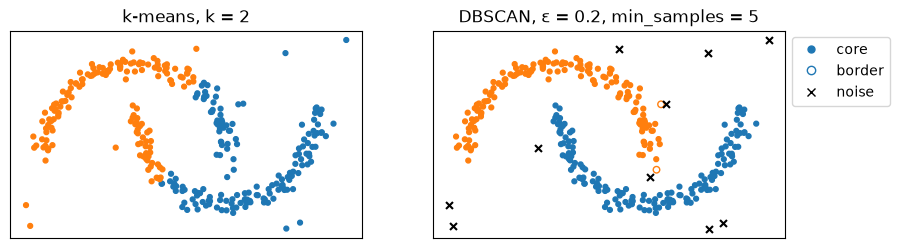

In [3]:
kmeans_labels = KMeans(n_clusters=2, random_state=0).fit_predict(X)
dbscan = DBSCAN(eps=0.2, min_samples=5).fit(X)
labels = dbscan.labels_
is_core = np.zeros(len(X), dtype=bool)
is_core[dbscan.core_sample_indices_] = True

is_border = ~is_core & (labels != -1)
n_clusters, n_noise = count(labels)
print(f"DBSCAN: {n_clusters} clusters, {n_noise} noise points")
print(f"{is_core.sum()} core points, {is_border.sum()} border points")

# ARI on the 300 points of the moons, compared with the two moons
ari_kmeans = adjusted_rand_score(moon_labels, kmeans_labels[:300])
ari_dbscan = adjusted_rand_score(moon_labels, labels[:300])
print(f"ARI on the moons: k-means {ari_kmeans:.2f}, DBSCAN {ari_dbscan:.2f}")
kept = labels != -1
silhouette_kmeans = silhouette_score(X, kmeans_labels)
silhouette_dbscan = silhouette_score(X[kept], labels[kept])
print(f"Mean silhouette: k-means {silhouette_kmeans:.2f}, ", end="")
print(f"DBSCAN {silhouette_dbscan:.2f} (without the noise)")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
show(left, X, kmeans_labels, "k-means, k = 2")
show(right, X, labels, "DBSCAN, ε = 0.2, min_samples = 5", core=is_core)
right.legend(
  handles=[
    plt.Line2D([], [], marker="o", ls="", color="C0", markersize=5, label="core"),
    plt.Line2D(
      [], [], marker="o", ls="", mfc="white", mec="C0", markersize=6, label="border"
    ),
    plt.Line2D([], [], marker="x", ls="", color="k", label="noise"),
  ],
  loc="upper left",
  bbox_to_anchor=(1, 1),
)
plt.show()

K-means cuts the moons into two halves (ARI 0.20): it looks for round groups around centroids, and each boundary is halfway between two centroids. DBSCAN follows the density: it finds the two moons (ARI 1.00) and marks as noise 10 of the 15 added points (the other 5 fell on a moon).

The mean silhouette still prefers k-means (0.48 against 0.32): it favors round, compact clusters. It is one clue among others.

## Choosing ε: the k-distance Plot

For each point, the distance to its 5th neighbor (5 = `min_samples`, the point counted among its neighbors as in DBSCAN), sorted. In dense areas, this distance is small; for the noise, it is large. Take ε at the elbow, where the curve turns up.

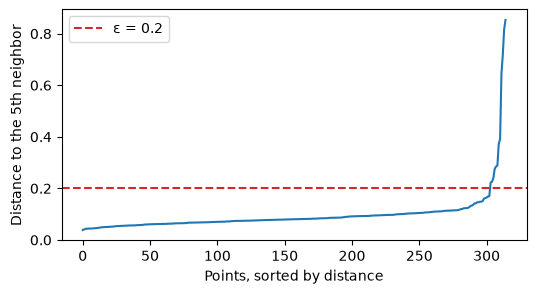

In [4]:
# Distance of each point to its 5th neighbor, itself included (as min_samples)
neighbors = NearestNeighbors(n_neighbors=5).fit(X)
distances = np.sort(neighbors.kneighbors(X)[0][:, -1])

plt.figure(figsize=(6, 3))
plt.plot(distances)
plt.axhline(0.2, color="C3", ls="--", label="ε = 0.2")
plt.xlabel("Points, sorted by distance")
plt.ylabel("Distance to the 5th neighbor")
plt.legend()
plt.show()

Three values of ε around the elbow:

ε = 0.1: 11 cluster(s), 29 noise points
ε = 0.2: 2 cluster(s), 10 noise points
ε = 0.3: 1 cluster(s), 6 noise points


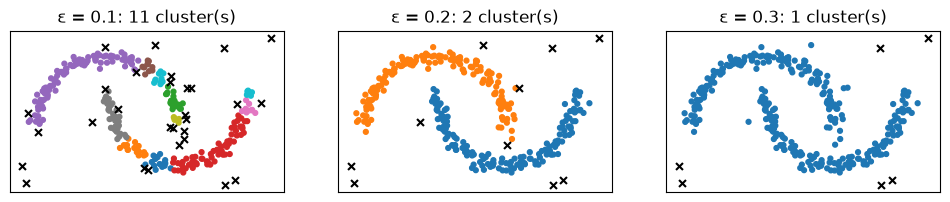

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, eps in zip(axes, (0.1, 0.2, 0.3)):
  labels = DBSCAN(eps=eps, min_samples=5).fit(X).labels_
  n_clusters, n_noise = count(labels)
  print(f"ε = {eps}: {n_clusters} cluster(s), {n_noise} noise points")
  show(ax, X, labels, f"ε = {eps}: {n_clusters} cluster(s)")
plt.show()

ε too small (0.1): the moons break up into 11 clusters, with 29 noise points. ε too large (0.3): the two moons merge into a single cluster. At the elbow, ε = 0.2 separates them.

## HDBSCAN

[HDBSCAN](https://scikit-learn.org/stable/modules/clustering.html#hdbscan) (`sklearn.cluster.HDBSCAN`, scikit-learn ≥ 1.3) is DBSCAN over every value of ε: it keeps the clusters that last longest as ε varies. No ε to set, varying densities, and a single setting: the minimum cluster size (`min_cluster_size`).

On the moons, without ε:

In [6]:
# copy=True: HDBSCAN doesn't modify X (the default from scikit-learn 1.10)
labels = HDBSCAN(min_cluster_size=10, copy=True).fit(X).labels_
n_clusters, n_noise = count(labels)
print(f"HDBSCAN: {n_clusters} clusters, {n_noise} noise points, ", end="")
print(f"ARI on the moons {adjusted_rand_score(moon_labels, labels[:300]):.2f}")

HDBSCAN: 2 clusters, 11 noise points, ARI on the moons 0.99


On three groups of different densities (those of scikit-learn's HDBSCAN example), a single ε does not fit every cluster:

DBSCAN, ε = 0.2: 6 clusters, 83 noise points, ARI 0.76
DBSCAN, ε = 0.5: 2 clusters, 3 noise points, ARI 0.56
HDBSCAN, min_cluster_size = 20: 3 clusters, 78 noise points, ARI 0.85


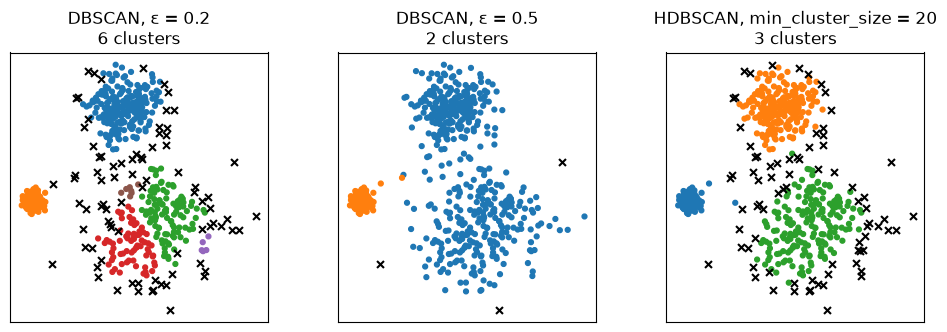

In [7]:
blobs, blob_labels = make_blobs(
  n_samples=750,
  centers=[[1, 1], [-1, -1], [1.5, -1.5]],
  cluster_std=[0.4, 0.1, 0.75],
  random_state=0,
)
models = {
  "DBSCAN, ε = 0.2": DBSCAN(eps=0.2, min_samples=5),
  "DBSCAN, ε = 0.5": DBSCAN(eps=0.5, min_samples=5),
  "HDBSCAN, min_cluster_size = 20": HDBSCAN(min_cluster_size=20, copy=True),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (title, model) in zip(axes, models.items()):
  labels = model.fit(blobs).labels_
  n_clusters, n_noise = count(labels)
  ari = adjusted_rand_score(blob_labels, labels)
  print(f"{title}: {n_clusters} clusters, {n_noise} noise points, ARI {ari:.2f}")
  show(ax, blobs, labels, f"{title}\n{n_clusters} clusters")
plt.show()

In [8]:
for size in (10, 40):
  labels = HDBSCAN(min_cluster_size=size, copy=True).fit(blobs).labels_
  n_clusters, n_noise = count(labels)
  print(
    f"HDBSCAN, min_cluster_size = {size}: {n_clusters} clusters, {n_noise} noise points"
  )

HDBSCAN, min_cluster_size = 10: 3 clusters, 48 noise points
HDBSCAN, min_cluster_size = 40: 3 clusters, 101 noise points


With ε = 0.2, the sparsest group breaks up (6 clusters, 83 noise points); with ε = 0.5, the two groups on the right merge (2 clusters). HDBSCAN finds the 3 groups, and keeps them for a minimum size from 10 to 40: a setting that matters little. It puts the scattered points of the sparsest group in the noise, which lowers its ARI.